In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
torch.manual_seed(42)

import pickle
with open('./data/vocab_pickle.pkl', 'rb') as file:
    vocab = pickle.load(file)

print("Vocabulary Size:", len(vocab))
print("Vocabulary Preview:", dict(list(vocab.items())[:20]))

Vocabulary Size: 1002
Vocabulary Preview: {'to': 2, 'the': 3, 'and': 4, 'a': 5, 'in': 6, 'of': 7, 'you': 8, 'that': 9, 'is': 10, 'it': 11, 'can': 12, 'i': 13, 'for': 14, 'they': 15, 'be': 16, 'have': 17, 'are': 18, 'students': 19, 'people': 20, 'not': 21}


In [2]:
## YOUR SOLUTION HERE ##
class SimpleNNWithEmbedding(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, output_size):
        super(SimpleNNWithEmbedding, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.fc1 = nn.Linear(embed_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.embedding(x)
        x = torch.mean(x, dim=1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x
        
vocab_size = len(vocab)
embed_size = 50
hidden_size = 100
output_size = 2

text_classifier_model = SimpleNNWithEmbedding(vocab_size, embed_size, hidden_size, output_size)
state_dict = torch.load("./models/text_classifier_nn.pth")
text_classifier_model.load_state_dict(state_dict)
text_classifier_model.eval()

embedding_layer = text_classifier_model.embedding.weight.detach().cpu().numpy()

# Show output
print(f"Embedding shape:", embedding_layer.shape)

Embedding shape: (1002, 50)


In [3]:
from sklearn.metrics.pairwise import cosine_similarity

## YOUR SOLUTION HERE ##
def token_similarity(token1, token2, vocab, embedding_layer):
    i, j = vocab[token1], vocab[token2]
    sim = cosine_similarity(embedding_layer[i].reshape(1, -1), embedding_layer[j].reshape(1, -1))[0][0]
    return sim

sim1 = token_similarity("school", "student", vocab, embedding_layer)
sim2 = token_similarity("school", "work", vocab, embedding_layer)
sim3 = token_similarity("school", "phone", vocab, embedding_layer)

# Show output - Cosine similarity scores for token pairs
print(f"Cosine Similarity (school, student): {sim1:.5}")
print(f"Cosine Similarity (school, work): {sim2:.5}")
print(f"Cosine Similarity (school, phone): {sim3:.5}")

Cosine Similarity (school, student): 0.0012185
Cosine Similarity (school, work): 0.37594
Cosine Similarity (school, phone): -0.17877


In [6]:
from sklearn.manifold import TSNE

def plot_embeddings(tokens, vocab, embeddings):
    idxs = [vocab[w] for w in tokens if w in vocab]
    pts = embeddings[idxs]
    plt.figure(figsize=(7,6))
    plt.scatter(pts[:,0], pts[:,1], s=24)
    for (x,y), w in zip(pts, tokens):
        if w in vocab:
            plt.text(x+0.01, y+0.01, w, fontsize=9)
    plt.title("Word Embeddings (t-SNE, 2D)")
    plt.xlabel("dim-1"); plt.ylabel("dim-2")
    plt.tight_layout()
    plt.show()

## YOUR SOLUTION HERE ##
embeddings_2d = TSNE(n_components=2, random_state=42).fit_transform(embedding_layer)
tokens_to_plot = ["school", "students", "work", "phone", "people", "life", "positive", "negative", "company"]

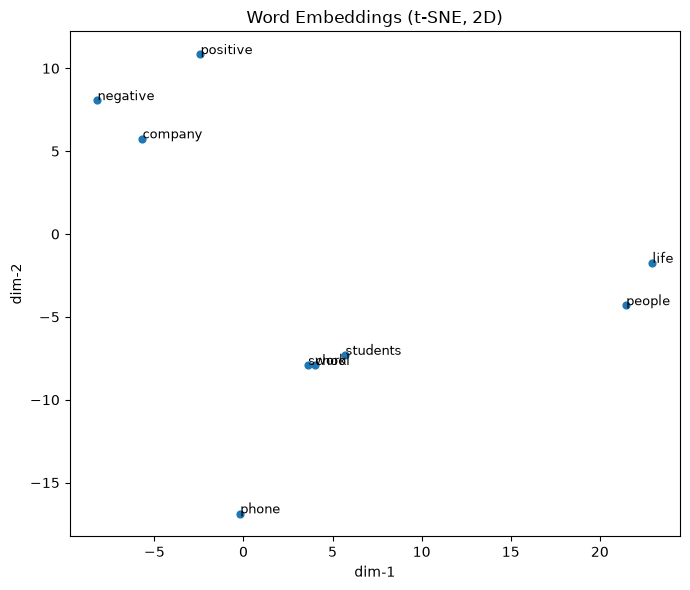

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

# Show output - Visualize Embeddings
plot_embeddings(tokens_to_plot, vocab, embeddings_2d)